In [1]:
!hdfs dfs -D dfs.replication=1 -cp -f data/*.jsonl hdfs://nn:9000/
!hdfs dfs -D dfs.replication=1 -cp -f data/*.csv hdfs://nn:9000/

In [2]:
from pyspark.sql import SparkSession
spark = (SparkSession.builder.appName("cs544")
         .master("spark://boss:7077")
         .config("spark.executor.memory", "1G")
         .config("spark.sql.warehouse.dir", "hdfs://nn:9000/user/hive/warehouse")
         .enableHiveSupport()
         .getOrCreate())

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/04/08 06:30:04 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [3]:
problems_df = spark.read.json("hdfs://nn:9000/problems.jsonl")

In [4]:
problems_df.limit(5).show()


[Stage 1:>                                                          (0 + 1) / 1]

+-------------+--------+---------+---------+---------------+----------+---------------+-------------------------+------------------+--------------------+-------------+----------+------------+------+----------+
|cf_contest_id|cf_index|cf_points|cf_rating|        cf_tags|difficulty|generated_tests|is_description_translated|memory_limit_bytes|                name|private_tests|problem_id|public_tests|source|time_limit|
+-------------+--------+---------+---------+---------------+----------+---------------+-------------------------+------------------+--------------------+-------------+----------+------------+------+----------+
|          322|       A|    500.0|     1000|            [0]|         7|             93|                    false|         256000000|322_A. Ciel and D...|           45|         1|           2|     2|         1|
|          760|       D|   1000.0|     1600|         [1, 2]|        10|             51|                    false|         256000000|  760_D. Travel Card|       

In [5]:
problems_df.write.mode("overwrite").saveAsTable("problems")

26/04/08 06:30:16 WARN ObjectStore: Version information not found in metastore. hive.metastore.schema.verification is not enabled so recording the schema version 2.3.0
26/04/08 06:30:16 WARN ObjectStore: setMetaStoreSchemaVersion called but recording version is disabled: version = 2.3.0, comment = Set by MetaStore UNKNOWN@172.18.0.2
26/04/08 06:30:18 WARN SessionState: METASTORE_FILTER_HOOK will be ignored, since hive.security.authorization.manager is set to instance of HiveAuthorizerFactory.
26/04/08 06:30:18 WARN HiveConf: HiveConf of name hive.internal.ss.authz.settings.applied.marker does not exist


In [6]:
solutions_df = spark.read.json("hdfs://nn:9000/solutions.jsonl")
solutions_df.write.mode("overwrite").bucketBy(4, "language").saveAsTable("solutions")

In [12]:
!hdfs dfs -mkdir -p /data

!hdfs dfs -put /nb/data/languages.csv /data/
!hdfs dfs -put /nb/data/problem_tests.csv /data/
!hdfs dfs -put /nb/data/sources.csv /data/
!hdfs dfs -put /nb/data/tags.csv /data/

languages_df = spark.read.csv("hdfs://nn:9000/languages.csv", header=True, inferSchema=True)
languages_df.createOrReplaceTempView("languages")
problem_tests_df = spark.read.csv("hdfs://nn:9000/problem_tests.csv", header=True, inferSchema=True)
problem_tests_df.createOrReplaceTempView("problem_tests")
sources_df = spark.read.csv("hdfs://nn:9000/sources.csv", header=True, inferSchema=True)
sources_df.createOrReplaceTempView("sources")
tags_df = spark.read.csv("hdfs://nn:9000/tags.csv", header=True, inferSchema=True)
tags_df.createOrReplaceTempView("tags")

put: `/data/languages.csv': File exists
put: `/data/problem_tests.csv': File exists
put: `/data/sources.csv': File exists
put: `/data/tags.csv': File exists


In [13]:
#Q1: How many problems are there with a cf_rating of at least 1600, having private_tests, and a name containing "_A." (Case Sensitive)?
rdd_count = problems_df.rdd.filter(
    lambda p: p['cf_rating'] >= 1600 and p['private_tests'] and "_A." in p['name']
).count()

from pyspark.sql.functions import col
dataframe_count = problems_df.filter(
    (col("cf_rating") >= 1600) &
    (col("private_tests") >= 1) &
    (col("name").contains("_A."))
).count()

sql_count = problems_df.selectExpr("*").where("cf_rating >= 1600 AND private_tests >= 1 AND name LIKE '%_A.%'").count()

(rdd_count, dataframe_count, sql_count)

(217, 217, 217)

In [16]:
#Q2: How many correct PYTHON3 solutions are from CODEFORCES?
count = solutions_df.join(problems_df, "problem_id") \
    .join(sources_df, problems_df.source == sources_df.source) \
    .filter((solutions_df.language == "PYTHON3") & 
            (solutions_df.is_correct == True) & 
            (sources_df.source_name == "CODEFORCES")) \
    .count()

count

10576

In [17]:
#Q3: How many problems are of easy/medium/hard difficulty?
result_df = spark.sql("""
    SELECT difficulty_category, COUNT(*) AS count
    FROM (
        SELECT 
            CASE
                WHEN difficulty <= 5 THEN 'Easy'
                WHEN difficulty <= 10 THEN 'Medium'
                ELSE 'Hard'
            END AS difficulty_category
        FROM problems
    ) t
    GROUP BY difficulty_category
""")

difficulty_counts = {
    row['difficulty_category']: row['count']
    for row in result_df.collect()
}

difficulty_counts


{'Easy': 409, 'Medium': 5768, 'Hard': 2396}

In [18]:
#Q4: What tables/views are in our warehouse?
tables = spark.catalog.listTables()
table_dict = {}

for t in tables:
    table_dict[t.name] = t.isTemporary

table_dict

{'problems': False,
 'solutions': False,
 'languages': True,
 'problem_tests': True,
 'sources': True,
 'tags': True}

In [19]:
#Q5: Does the query plan for a GROUP BY on solutions data need to shuffle/exchange rows if the data is pre-bucketed?
spark.sql("""
SELECT language, COUNT(*)
FROM solutions
GROUP BY language
""").explain(True)

== Parsed Logical Plan ==
'Aggregate ['language], ['language, unresolvedalias('COUNT(1))]
+- 'UnresolvedRelation [solutions], [], false

== Analyzed Logical Plan ==
language: string, count(1): bigint
Aggregate [language#535], [language#535, count(1) AS count(1)#538L]
+- SubqueryAlias spark_catalog.default.solutions
   +- Relation spark_catalog.default.solutions[is_correct#534,language#535,problem_id#536L,solution#537] parquet

== Optimized Logical Plan ==
Aggregate [language#535], [language#535, count(1) AS count(1)#538L]
+- Project [language#535]
   +- Relation spark_catalog.default.solutions[is_correct#534,language#535,problem_id#536L,solution#537] parquet

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[language#535], functions=[count(1)], output=[language#535, count(1)#538L])
   +- HashAggregate(keys=[language#535], functions=[partial_count(1)], output=[language#535, count#541L])
      +- FileScan parquet spark_catalog.default.solutions[language#535] 

In [20]:
#Q6: Does caching make it faster to compute averages over a subset of a bigger dataset?
from pyspark.sql.functions import avg
import time

subset_df = problem_tests_df.filter(problem_tests_df.is_generated == False)

start1 = time.time()
subset_df.select(avg("input_chars"), avg("output_chars")).show()
time1 = time.time() - start1
subset_df.cache()
start2 = time.time()
subset_df.select(avg("input_chars"), avg("output_chars")).show()
time2 = time.time() - start2
start3 = time.time()
subset_df.select(avg("input_chars"), avg("output_chars")).show()
time3 = time.time() - start3

subset_df.unpersist()

[time1, time2, time3]

+------------------+-----------------+
|  avg(input_chars)|avg(output_chars)|
+------------------+-----------------+
|57.884318656493754|878.0121265078214|
+------------------+-----------------+

+------------------+-----------------+
|  avg(input_chars)|avg(output_chars)|
+------------------+-----------------+
|57.884318656493754|878.0121265078214|
+------------------+-----------------+

+------------------+-----------------+
|  avg(input_chars)|avg(output_chars)|
+------------------+-----------------+
|57.884318656493754|878.0121265078214|
+------------------+-----------------+



[0.6156129837036133, 0.8625016212463379, 0.14980125427246094]

In [23]:
#Q7: How many JAVA solutions are there?
import os
from google import genai

client = genai.Client(
    vertexai=True,
    project=os.environ['GOOGLE_CLOUD_PROJECT'],
    location='us-central1',
)

def human_query(question: str) -> int:
    tables = ["problems", "solutions", "languages", "problem_tests", "sources","tags"]
    schema_text = ""
    for t in tables:
        cols = spark.catalog.listColumns(t)
        schema_text += f"Table {t}: {', '.join([c.name+'('+c.dataType+')' for c in cols])}\n"
    
    prompt = f"""
    You are given Spark SQL tables with the following schema:
    {schema_text}
    Generate a Spark SQL query that answers the question: "{question}"
    ONLY return the query itself, nothing else, no explanations, no comments.
    Make sure the query returns a single numeric result.
    """
    
    response = client.models.generate_content(
        model='gemini-2.5-pro',
        contents=prompt,
        config={'temperature': 0}
    )
    
    query = response.text.strip().rstrip(";")
    
    result = spark.sql(query).collect()[0][0]
    return int(result)


In [24]:
#Q7: How many JAVA solutions are there?
java_solutions = human_query("How many JAVA solutions are there?")
java_solutions

28722

In [25]:
#Q8: What is the maximum memory limit in bytes?
max_memory = human_query("What is the maximum memory limit in bytes?")
max_memory

1024000000

In [ ]:
from pyspark.sql.functions import col
from pyspark.sql.types import DoubleType
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import DecisionTreeRegressor
from pyspark.ml import Pipeline

codeforces_df = solutions_df.join(problems_df, "problem_id") \
                            .join(sources_df, problems_df.source == sources_df.source) \
                            .filter((sources_df.source_name == "CODEFORCES")) \
                            .select(
                                problems_df.problem_id,
                                "cf_rating",
                                "difficulty",
                                "time_limit",
                                "memory_limit_bytes"
                            ).distinct()

for c in ["cf_rating", "difficulty", "time_limit", "memory_limit_bytes"]:
    codeforces_df = codeforces_df.withColumn(c, col(c).cast(DoubleType()))

train_df = codeforces_df.filter((col("cf_rating") > 0) & (col("problem_id") % 2 == 0))
test_df  = codeforces_df.filter((col("cf_rating") > 0) & (col("problem_id") % 2 == 1))
missing_df = codeforces_df.filter(col("cf_rating") == 0)

In [60]:
#Q9: Do the problems with a missing cf_rating appear more or less challenging than other problems?
feature_cols = ["difficulty", "time_limit", "memory_limit_bytes"]
assembler = VectorAssembler(inputCols=feature_cols, outputCol="features")
dt = DecisionTreeRegressor(labelCol="cf_rating", featuresCol="features", maxDepth=5)
pipeline = Pipeline(stages=[assembler, dt])
model = pipeline.fit(train_df)
predictions_missing = model.transform(missing_df)
train_avg = train_df.agg({"cf_rating": "avg"}).collect()[0][0]
test_avg  = test_df.agg({"cf_rating": "avg"}).collect()[0][0]
pred_avg  = predictions_missing.agg({"prediction": "avg"}).collect()[0][0]

(train_avg, test_avg, pred_avg)

(1887.4801061007959, 1892.2749067661161, 1863.266250123502)

   depth     train      test
0      1  0.424714  0.456078
1      2  0.530684  0.550369
2      3  0.570706  0.592661
3      5  0.598899  0.603269
4      7  0.615172  0.602840
5     10  0.626975  0.585876
6     15  0.630611  0.582296
7     20  0.630611  0.582296
8     25  0.630611  0.582296
9     30  0.630611  0.582296


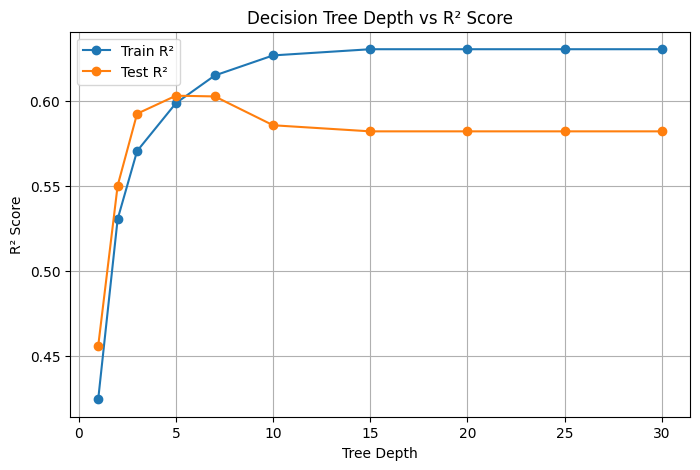

'{"depth":{"0":1,"1":2,"2":3,"3":5,"4":7,"5":10,"6":15,"7":20,"8":25,"9":30},"train":{"0":0.4247142732,"1":0.5306837116,"2":0.5707055496,"3":0.5988990584,"4":0.615172273,"5":0.6269747418,"6":0.6306112195,"7":0.6306112195,"8":0.6306112195,"9":0.6306112195},"test":{"0":0.4560775207,"1":0.5503693039,"2":0.5926605893,"3":0.6032693291,"4":0.6028397955,"5":0.5858760963,"6":0.5822960665,"7":0.5822960665,"8":0.5822960665,"9":0.5822960665}}'

In [64]:
#Q10: How does tree depth impact the quality of predictions?
from pyspark.ml.evaluation import RegressionEvaluator
import pandas as pd
import matplotlib.pyplot as plt
feature_cols = ["difficulty", "time_limit", "memory_limit_bytes"]
assembler = VectorAssembler(inputCols=feature_cols, outputCol="features")
depths = [1, 2, 3, 5, 7, 10, 15, 20, 25, 30]
evaluator = RegressionEvaluator(labelCol="cf_rating", predictionCol="prediction", metricName="r2")
results = []
for depth in depths:
    dt = DecisionTreeRegressor(labelCol="cf_rating", featuresCol="features", maxDepth=depth)
    pipeline = Pipeline(stages=[assembler, dt])
    model = pipeline.fit(train_df)
    pred_train = model.transform(train_df)
    pred_test  = model.transform(test_df)
    r2_train = evaluator.evaluate(pred_train)
    r2_test  = evaluator.evaluate(pred_test)
    results.append({"depth": depth, "train": r2_train, "test": r2_test})

df_r2 = pd.DataFrame(results)
print(df_r2)

plot_df = pd.DataFrame(results)

plt.figure(figsize=(8,5))
plt.plot(plot_df["depth"], plot_df["train"], marker='o', label="Train R²")
plt.plot(plot_df["depth"], plot_df["test"], marker='o', label="Test R²")
plt.xlabel("Tree Depth")
plt.ylabel("R² Score")
plt.title("Decision Tree Depth vs R² Score")
plt.legend()
plt.grid(True)
plt.show()

plot_df.to_json()